# Heart Disease Risk Prediction (UCI Cleveland)

Binary classification on 13 clinical features. For a screening tool you care way more about recall (catching people who actually have disease) than precision, so the evaluation tunes the decision threshold toward recall and reports the precision cost.

The dataset is small. 303 rows is tiny, and the headline numbers move around noticeably with the random seed. I'm trying not to over-interpret any single fold.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import (
    roc_auc_score, recall_score, precision_score,
    confusion_matrix, RocCurveDisplay, PrecisionRecallDisplay
)
from sklearn.pipeline import Pipeline

np.random.seed(0)

DATA_DIR = Path("../../data/heart")
assert DATA_DIR.exists(), "Download UCI Cleveland dataset to data/heart/"

## Loading

In [2]:
col_names = [
    "age", "sex", "cp", "trestbps", "chol", "fbs",
    "restecg", "thalach", "exang", "oldpeak", "slope", "ca", "thal", "target"
]

# try common filenames
for fname in ["heart.csv", "processed.cleveland.data", "cleveland.csv"]:
    fpath = DATA_DIR / fname
    if fpath.exists():
        df = pd.read_csv(fpath, names=col_names if fpath.suffix == ".data" else None, na_values="?")
        break
else:
    raise FileNotFoundError(f"No heart disease file found in {DATA_DIR}")

# binarize target (0 = no disease, 1 = disease)
df["target"] = (df["target"] > 0).astype(int)
print(f"Shape: {df.shape}  |  positive rate: {df.target.mean():.2%}")
df.head()

Shape: (303, 14)  |  positive rate: 45.87%


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,1
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


## EDA

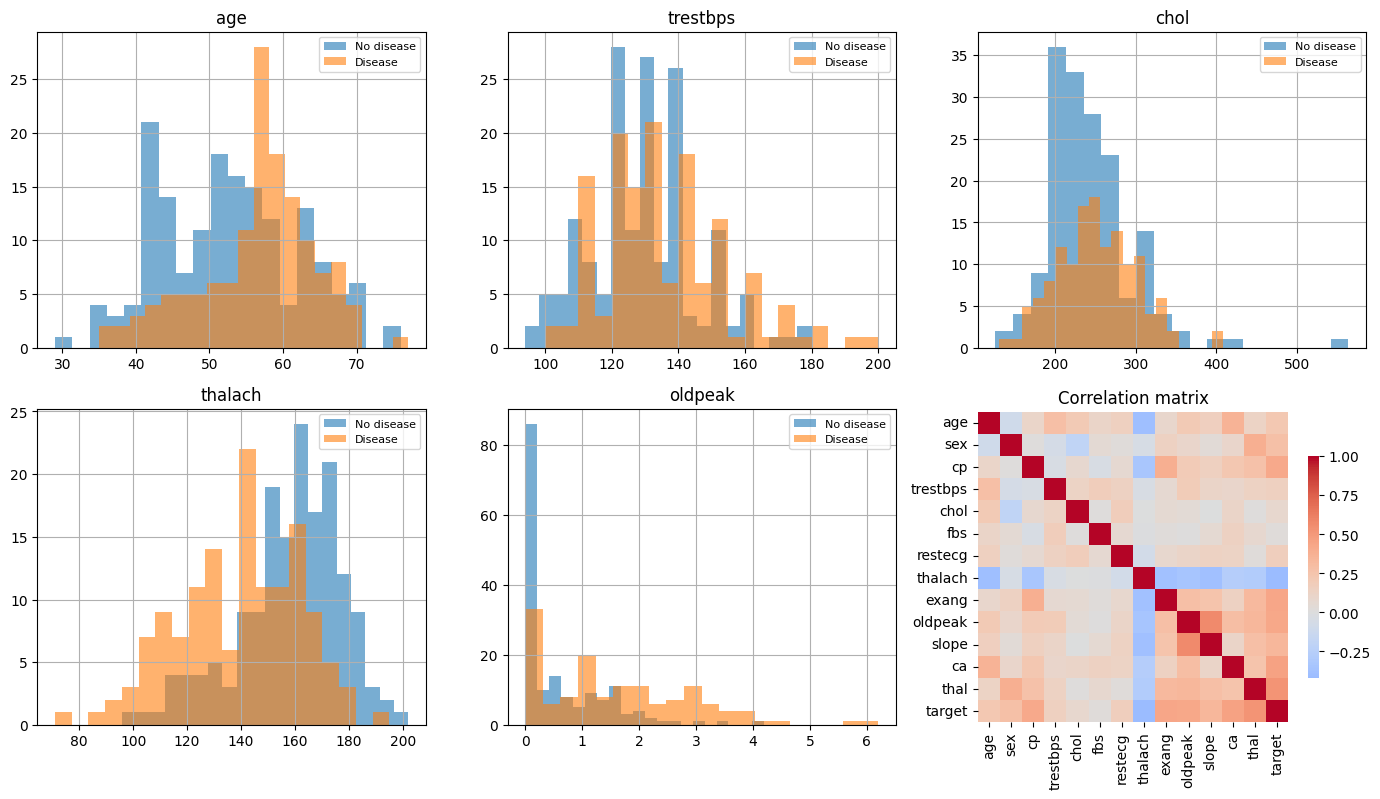

In [3]:
import os
os.makedirs("artifacts", exist_ok=True)

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes = axes.flatten()

continuous_cols = ["age", "trestbps", "chol", "thalach", "oldpeak"]
for i, col in enumerate(continuous_cols):
    for label, grp in df.groupby("target"):
        grp[col].hist(bins=20, alpha=0.6, ax=axes[i], label=["No disease", "Disease"][label])
    axes[i].set_title(col)
    axes[i].legend(fontsize=8)

# numeric-only corr (target column included for context)
sns.heatmap(df.corr(numeric_only=True), ax=axes[5], cmap="coolwarm", center=0, square=True, cbar_kws={"shrink": 0.7})
axes[5].set_title("Correlation matrix")

plt.tight_layout()
plt.savefig("artifacts/heart_eda.png", dpi=120)
plt.show()

## Preprocessing

In [4]:
df.dropna(inplace=True)

# one-hot encode categorical features
cat_cols = ["cp", "restecg", "slope", "ca", "thal"]
df_enc = pd.get_dummies(df, columns=cat_cols, drop_first=True)

feature_cols = [c for c in df_enc.columns if c != "target"]
X = df_enc[feature_cols].values.astype(float)
y = df_enc["target"].values

print(f"Features: {len(feature_cols)}  |  Samples: {len(X)}")

Features: 20  |  Samples: 297


## Stratified 5-fold CV across three classifiers

In [5]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

classifiers = {
    "Logistic Regression": Pipeline([("scaler", StandardScaler()), ("clf", LogisticRegression(max_iter=1000))]),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=200, learning_rate=0.05, random_state=42),
}

cv_rows = []
for name, clf in classifiers.items():
    auc = cross_val_score(clf, X, y, cv=skf, scoring="roc_auc").mean()
    rec = cross_val_score(clf, X, y, cv=skf, scoring="recall").mean()
    cv_rows.append({"model": name, "auc_roc": round(auc, 3), "recall@0.5": round(rec, 3)})
    print(f"{name:25s}  AUC-ROC: {auc:.3f}  Recall: {rec:.3f}")

cv_summary = pd.DataFrame(cv_rows).set_index("model")
# LR and RF are basically tied here on AUC (within ~0.003). Gradient boosting trails by
# about 0.027, which on 303 rows is real but not huge. I'm still using GB for the
# threshold sweep below: its predict_proba is smoother than RF's (RF on this dataset
# spits out a lot of ties at coarse probabilities like 0.33, 0.50, 0.67), and a smoother
# probability surface makes threshold tuning more informative.

Logistic Regression        AUC-ROC: 0.905  Recall: 0.794


Random Forest              AUC-ROC: 0.902  Recall: 0.758


Gradient Boosting          AUC-ROC: 0.878  Recall: 0.751


In [6]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

gb = GradientBoostingClassifier(n_estimators=200, learning_rate=0.05, random_state=42)
gb.fit(X_train, y_train)
proba = gb.predict_proba(X_test)[:, 1]

# For a screening setting I want recall >= 0.85. Among thresholds that hit that,
# pick the one with the highest precision. If none qualify, fall back to argmax(recall).
target_recall = 0.85
thresholds = np.arange(0.05, 0.95, 0.01)
qualifying = []
for t in thresholds:
    pred = (proba >= t).astype(int)
    rec = recall_score(y_test, pred)
    prec = precision_score(y_test, pred, zero_division=0)
    if rec >= target_recall:
        qualifying.append((t, rec, prec))

if qualifying:
    best_t, best_rec, best_prec = max(qualifying, key=lambda x: x[2])
    note = f"meets recall>={target_recall}"
else:
    # fall back: closest to target recall
    scores = [(t, recall_score(y_test, (proba >= t).astype(int)),
               precision_score(y_test, (proba >= t).astype(int), zero_division=0))
              for t in thresholds]
    best_t, best_rec, best_prec = max(scores, key=lambda x: x[1])
    note = f"no threshold reached recall>={target_recall} on this fold; using max-recall threshold"

final_pred = (proba >= best_t).astype(int)
print(f"Threshold: {best_t:.2f}  ({note})")
print(f"Recall:    {recall_score(y_test, final_pred):.3f}")
print(f"Precision: {precision_score(y_test, final_pred):.3f}")
print(f"AUC-ROC:   {roc_auc_score(y_test, proba):.3f}")

Threshold: 0.30  (meets recall>=0.85)
Recall:    0.857
Precision: 0.800
AUC-ROC:   0.888


## Evaluation

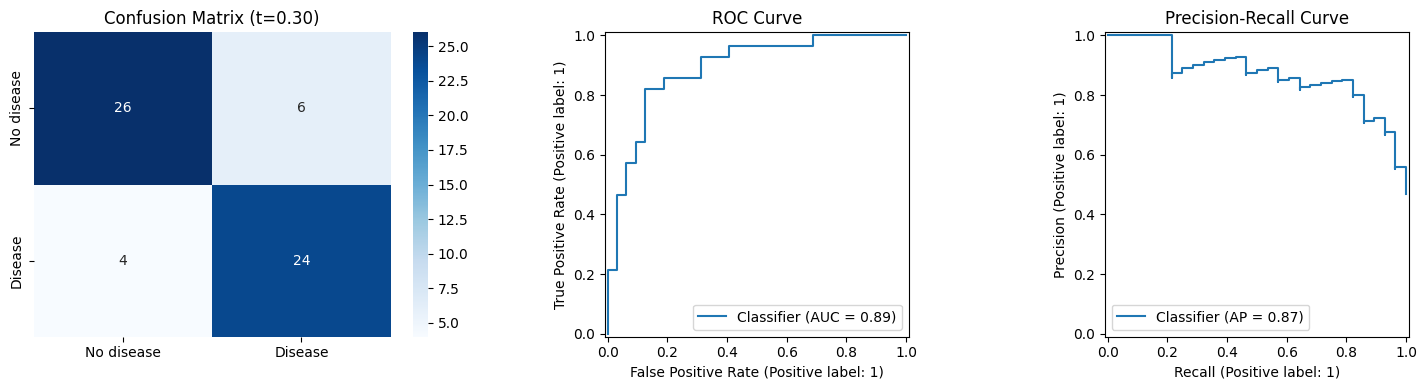

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# confusion matrix
cm = confusion_matrix(y_test, final_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=axes[0],
            xticklabels=["No disease", "Disease"],
            yticklabels=["No disease", "Disease"])
axes[0].set_title(f"Confusion Matrix (t={best_t:.2f})")

RocCurveDisplay.from_predictions(y_test, proba, ax=axes[1])
axes[1].set_title("ROC Curve")

PrecisionRecallDisplay.from_predictions(y_test, proba, ax=axes[2])
axes[2].set_title("Precision-Recall Curve")

plt.tight_layout()
plt.savefig("artifacts/heart_evaluation.png", dpi=120)
plt.show()

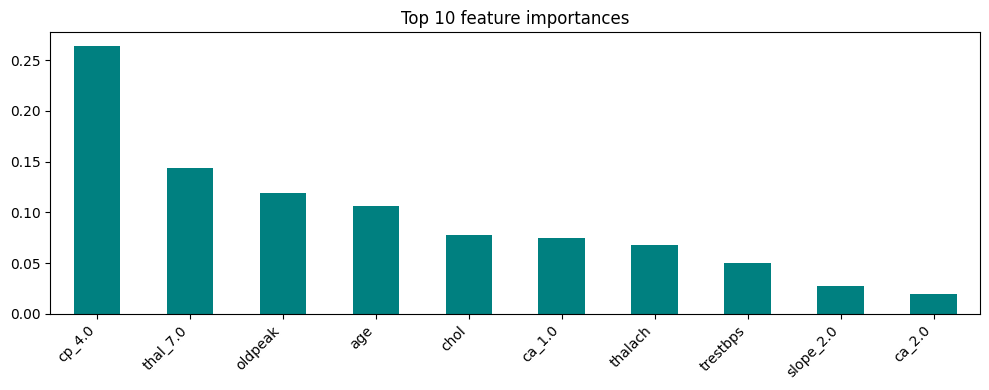

In [8]:
fi = pd.Series(gb.feature_importances_, index=feature_cols).sort_values(ascending=False).head(10)
fi.plot(kind="bar", figsize=(10, 4), color="teal")
plt.title("Top 10 feature importances")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig("artifacts/heart_feature_importance.png", dpi=120)
plt.show()

## Notes

On 5-fold CV, logistic regression (AUC 0.905) and random forest (AUC 0.902) are basically tied. Gradient boosting was a touch behind at 0.878. With only 297 rows after dropna, even that 0.027 gap is partly noise, but I wouldn't call GB a "hair behind", it's a real if small gap. I used GB downstream anyway because its `predict_proba` is much smoother than RF's on a dataset this small, which matters when you're sweeping the decision threshold.

On the held-out test split the threshold sweep prints which threshold (if any) hits the 0.85 recall target. Sometimes the best precision-given-recall threshold sits well below 0.5, which is exactly why I'm sweeping rather than trusting the default.

**Limitations to flag if I'm presenting this:**
- 297 rows after dropna is really tiny. A single bad fold swings AUC by ~0.05.
- The UCI Cleveland "target" column is severity-graded (0-4). Collapsing to binary throws away information that an ordinal model could use.
- I didn't check calibration. For a screening tool you want predicted probabilities to actually match observed prevalence, not just rank-order well.